# Scorecard Layer — From Probability to Committee Decision

**Context:** SME lending for a private debt fund
**Input:** the tuned random forest from `model_cs.ipynb` (loaded from `../models/`, not retrained)
**Output:** a 300 to 850 score, three risk bands, and a recommended action for each

A probability is not a decision. An investment committee does not want to read "0.43". It wants to know
whether to approve, send for closer review, or decline, and how often that call has been right.

This notebook converts the model's output into that form, and reports the **observed default rate inside each
band** on loans the model never saw.

**Method note.** Band cutoffs are set on out-of-fold predictions from the *training* data only. The test fold
is used once, to report how the bands perform. Choosing cutoffs by looking at test results would quietly
inflate the numbers.

---
*Personal project built on a public dataset. It uses no proprietary, client or employer data and does not represent the methods or views of any organisation.*

## 1. Setup and rebuild the same train and test split

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, warnings, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('../plots', exist_ok=True)
RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


The split must be identical to the one in `model_cs.ipynb`: same file, same seed, same stratification. The
sector tier map is loaded from disk because it was derived from the training fold only. Rebuilding it here
would risk drifting from what the model was trained on.

In [2]:
df = pd.read_csv('credit_data_engineered.csv')
cols     = joblib.load('../models/feature_columns.joblib')
tier_map = joblib.load('../models/sector_tier_map.joblib')
model    = joblib.load('../models/rf_tuned.joblib')

intent_cols = [c for c in df.columns if c.startswith('loan_intent_')]
df['loan_intent'] = df[intent_cols].idxmax(axis=1).str.replace('loan_intent_', '', regex=False)
df['sector_risk_score'] = df['loan_intent'].map(tier_map)

X = df[cols + ['loan_intent']]
y = df['loan_status']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

intent_test = X_test['loan_intent']
X_train, X_test = X_train[cols], X_test[cols]

p_test = model.predict_proba(X_test)[:, 1]
print(f"Train {len(X_train):,}   Test {len(X_test):,}")
print(f"Test AUC-ROC: {roc_auc_score(y_test, p_test):.4f}  (model_cs.ipynb reported 0.9293)")

Train 26,064   Test 6,517
Test AUC-ROC: 0.9293  (model_cs.ipynb reported 0.9293)


## 2. Turn probability into a score

Credit scores run the other way round from probabilities: higher is safer. The mapping is linear:

`score = 850 - 550 x P(default)`

so a certain default scores 300 and a certain good loan scores 850. This is a presentation choice, not a
statistical one. It makes no claim that the score is calibrated like a bureau score.

In [3]:
def to_score(p):
    return np.round(850 - 550 * np.asarray(p)).astype(int)

score_test = to_score(p_test)
print(pd.Series(score_test).describe().round(1).to_string())

count    6517.0
mean      673.0
std       166.4
min       300.0
25%       624.0
50%       731.0
75%       793.0
max       850.0


## 3. Set band cutoffs from the training data only

The forest has seen its own training rows, so its predictions on them are far too confident. To get honest
probabilities I use **out-of-fold** predictions: each training loan is scored by a forest that never saw it
(three folds, same hyperparameters as the tuned model).

Two policy rules, stated up front and applied mechanically. Each looks at a slice of 0.10 in predicted
probability, because a cumulative tail would be dominated by the large pile of near-certain defaults at the
top and would hide the middle of the range:

- **Low risk (approve):** the highest cutoff where the slice of loans just below it still defaults at **5% or less**.
- **High risk (decline):** the lowest cutoff where the slice of loans just above it defaults at **50% or more**, meaning more likely to default than not.
- Everything in between is **Medium (review)**.

These thresholds are a policy choice a committee would set for itself. 5% and 50% are defensible
starting points, not laws.

In [4]:
oof = cross_val_predict(
    clone(model), X_train, y_train,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    method='predict_proba', n_jobs=-1)[:, 1]
print(f"Out-of-fold AUC on training data: {roc_auc_score(y_train, oof):.4f}")

Out-of-fold AUC on training data: 0.9254


In [5]:
LOW_MAX_DEFAULT  = 0.05   # approve band may not exceed this observed default rate
HIGH_MIN_DEFAULT = 0.50   # decline band must be at least this risky

grid = np.round(np.arange(0.02, 0.99, 0.01), 2)

def slice_rate(lo, hi):
    k = (oof >= lo) & (oof < hi)
    return y_train[k].mean() if k.sum() >= 100 else np.nan

# Low: highest c where loans scored in [c-0.10, c) default at 5% or less
low_cut = max(c for c in grid if c >= 0.12 and slice_rate(c - 0.10, c) <= LOW_MAX_DEFAULT)
# High: lowest c where loans scored in [c, c+0.10) default at 50% or more
high_cut = min(c for c in grid if slice_rate(c, c + 0.10) >= HIGH_MIN_DEFAULT)
assert low_cut < high_cut, "cutoffs overlap"
print(f"Low-risk cutoff:  P(default) < {low_cut:.2f}   (score above {to_score(low_cut)})")
print(f"High-risk cutoff: P(default) >= {high_cut:.2f}  (score at or below {to_score(high_cut)})")
print(f"Training out-of-fold default rate, whole low band:  {y_train[oof < low_cut].mean()*100:.1f}%")
print(f"Training out-of-fold default rate, whole high band: {y_train[oof >= high_cut].mean()*100:.1f}%")

Low-risk cutoff:  P(default) < 0.20   (score above 740)
High-risk cutoff: P(default) >= 0.64  (score at or below 498)
Training out-of-fold default rate, whole low band:  3.0%
Training out-of-fold default rate, whole high band: 94.1%


## 4. Apply the bands to the test fold

This is the one time the test fold is used for the scorecard. Nothing is adjusted after this table.

In [6]:
BAND_ORDER = ['Low', 'Medium', 'High']
ACTION = {'Low': 'Approve', 'Medium': 'Review', 'High': 'Decline'}

def to_band(p):
    p = np.asarray(p)
    return np.where(p < low_cut, 'Low', np.where(p >= high_cut, 'High', 'Medium'))

res = pd.DataFrame({'p_default': p_test, 'score': score_test,
                    'band': to_band(p_test), 'default': y_test.values,
                    'intent': intent_test.values})
res['action'] = res['band'].map(ACTION)

low_score_cut  = to_score(low_cut)
high_score_cut = to_score(high_cut)
score_range = {
    'Low':    f"{low_score_cut + 1} to 850",
    'Medium': f"{high_score_cut + 1} to {low_score_cut}",
    'High':   f"300 to {high_score_cut}",
}

band_table = (res.groupby('band')
                 .agg(loans=('default', 'size'), defaults=('default', 'sum'),
                      default_rate=('default', 'mean'))
                 .reindex(BAND_ORDER))
band_table.insert(0, 'score_band', [score_range[b] for b in BAND_ORDER])
band_table.insert(1, 'action', [ACTION[b] for b in BAND_ORDER])
band_table['share_of_loans'] = band_table['loans'] / band_table['loans'].sum()
band_table['share_of_defaults'] = band_table['defaults'] / band_table['defaults'].sum()

show = band_table.copy()
show['default_rate']      = (show['default_rate'] * 100).round(1).astype(str) + '%'
show['share_of_loans']    = (show['share_of_loans'] * 100).round(1).astype(str) + '%'
show['share_of_defaults'] = (show['share_of_defaults'] * 100).round(1).astype(str) + '%'
print(show.to_string())
print(f"\nOverall test default rate: {y_test.mean()*100:.1f}%")

        score_band   action  loans  defaults default_rate share_of_loans share_of_defaults
band                                                                                      
Low     741 to 850  Approve   3043        81         2.7%          46.7%              5.7%
Medium  499 to 740   Review   2406       327        13.6%          36.9%             23.0%
High    300 to 498  Decline   1068      1014        94.9%          16.4%             71.3%

Overall test default rate: 21.8%


## 5. Does the ordering hold?

A scorecard is only useful if default rates rise steadily from Low to High. If a middle band defaulted less
than the low band, the bands would be meaningless.

Monotonic: Low < Medium < High
High-band default rate is 36x the low-band rate.


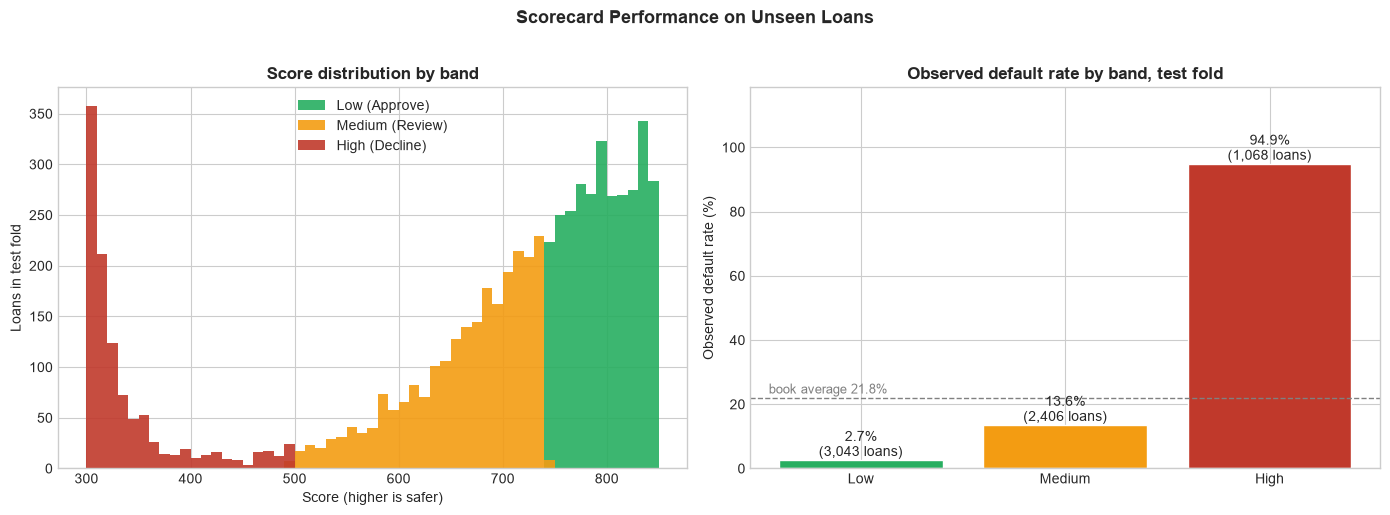

In [7]:
rates = band_table['default_rate']
assert rates['Low'] < rates['Medium'] < rates['High'], "bands are not monotonic"
print("Monotonic: Low < Medium < High")
print(f"High-band default rate is {rates['High']/rates['Low']:.0f}x the low-band rate.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colours = {'Low': '#27ae60', 'Medium': '#f39c12', 'High': '#c0392b'}

ax = axes[0]
for b in BAND_ORDER:
    ax.hist(res.loc[res.band == b, 'score'], bins=np.arange(300, 855, 10),
            color=colours[b], alpha=0.9, label=f'{b} ({ACTION[b]})')
ax.set_xlabel('Score (higher is safer)')
ax.set_ylabel('Loans in test fold')
ax.set_title('Score distribution by band', fontsize=12, fontweight='bold')
ax.legend()

ax = axes[1]
bars = ax.bar(BAND_ORDER, rates * 100, color=[colours[b] for b in BAND_ORDER], edgecolor='white')
for bar, b in zip(bars, BAND_ORDER):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2,
            f"{rates[b]*100:.1f}%\n({int(band_table.loc[b, 'loans']):,} loans)",
            ha='center', fontsize=10)
ax.axhline(y_test.mean() * 100, color='grey', linestyle='--', linewidth=1)
ax.text(-0.45, y_test.mean() * 100 + 1.5, 'book average 21.8%', color='grey', ha='left', fontsize=9)
ax.set_ylabel('Observed default rate (%)')
ax.set_ylim(0, max(rates * 100) * 1.25)
ax.set_title('Observed default rate by band, test fold', fontsize=12, fontweight='bold')

plt.suptitle('Scorecard Performance on Unseen Loans', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../plots/scorecard_bands.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. What it means in committee terms

Translating the bands into the questions a committee asks: how much do we approve without a second look, how
many defaults do we avoid, and how many good loans do we turn away?

In [8]:
total_good = int((y_test == 0).sum()); total_def = int(y_test.sum())
low  = res[res.band == 'Low']; high = res[res.band == 'High']; mid = res[res.band == 'Medium']

approved_share   = len(low) / len(res)
defaults_in_low  = int(low.default.sum())
defaults_caught  = int(high.default.sum())
good_declined    = int((high.default == 0).sum())
review_share     = len(mid) / len(res)
defaults_in_mid  = int(mid.default.sum())

print(f"Approved straight through (Low):   {len(low):,} loans, {approved_share*100:.1f}% of the book")
print(f"   of which defaulted:             {defaults_in_low:,}  ({low.default.mean()*100:.1f}%)")
print(f"Declined (High):                   {len(high):,} loans, {len(high)/len(res)*100:.1f}% of the book")
print(f"   defaults avoided:               {defaults_caught:,} of {total_def:,}  ({defaults_caught/total_def*100:.1f}% of all defaults)")
print(f"   good loans turned away:         {good_declined:,} of {total_good:,}  ({good_declined/total_good*100:.1f}% of good loans)")
print(f"Sent for analyst review (Medium):  {len(mid):,} loans, {review_share*100:.1f}% of the book")
print(f"   defaults sitting in this band:  {defaults_in_mid:,}  ({defaults_in_mid/total_def*100:.1f}% of all defaults)")

Approved straight through (Low):   3,043 loans, 46.7% of the book
   of which defaulted:             81  (2.7%)
Declined (High):                   1,068 loans, 16.4% of the book
   defaults avoided:               1,014 of 1,422  (71.3% of all defaults)
   good loans turned away:         54 of 5,095  (1.1% of good loans)
Sent for analyst review (Medium):  2,406 loans, 36.9% of the book
   defaults sitting in this band:  327  (23.0% of all defaults)


## 7. Does the score just repeat the sector view?

If the bands only mirrored the sector proxy, each band would be dominated by one loan intent. Below is the
mix of intents within each band, and the default rate for each intent within each band.

In [9]:
mix = (pd.crosstab(res['intent'], res['band'], normalize='columns')[BAND_ORDER] * 100).round(1)
print("Share of each band by loan intent (%)")
print(mix.to_string())

within = (res.pivot_table(index='intent', columns='band', values='default', aggfunc='mean')[BAND_ORDER] * 100).round(1)
print("\nObserved default rate within each intent and band (%)")
print(within.to_string())

Share of each band by loan intent (%)
band                Low  Medium  High
intent                               
DEBTCONSOLIDATION  12.9    16.4  24.3
EDUCATION          20.5    21.5  12.5
HOMEIMPROVEMENT     8.3    14.0  12.9
MEDICAL            16.2    17.7  24.1
PERSONAL           17.1    19.8  13.8
VENTURE            25.0    10.6  12.4

Observed default rate within each intent and band (%)
band               Low  Medium  High
intent                              
DEBTCONSOLIDATION  2.6    16.7  98.1
EDUCATION          2.9    12.0  94.8
HOMEIMPROVEMENT    5.2    14.8  94.2
MEDICAL            3.0    12.2  94.2
PERSONAL           4.0    12.0  92.5
VENTURE            0.5    15.7  93.9


## 8. Save the scored test set

Written locally for anyone who wants to inspect individual loans. The loan-level file is gitignored because
it can be regenerated by running this notebook. The small band summary is committed.

In [10]:
res.to_csv('scorecard_test_results.csv', index=False)
band_table.round(4).to_csv('scorecard_bands.csv')
print("Saved scorecard_test_results.csv and scorecard_bands.csv")
print(band_table[['score_band', 'action', 'loans', 'defaults', 'default_rate']].round(4).to_string())

Saved scorecard_test_results.csv and scorecard_bands.csv
        score_band   action  loans  defaults  default_rate
band                                                      
Low     741 to 850  Approve   3043        81        0.0266
Medium  499 to 740   Review   2406       327        0.1359
High    300 to 498  Decline   1068      1014        0.9494


## 9. What this scorecard cannot tell you

1. **The probabilities are not calibrated.** The forest was trained with balanced class weights, which
   inflates the predicted risk of the minority class. The score ranks loans well, and the *observed* default
   rate per band is the number to quote. The raw probability is not.
2. **The separation is probably flattering.** The model leans partly on the lender's own grade and interest
   rate. `model_cs.ipynb` shows the borrower-only model loses about 0.057 AUC. A fund writing its own paper
   should expect weaker separation than this table suggests.
3. **Consumer loans, not SMEs.** Cutoffs of 5% and 50% would be set very differently on a book with a target
   return in the teens and a handful of large tickets.
4. **One snapshot.** The bands cannot see a borrower deteriorating over time.

The method carries over to a real book. The cutoffs and the observed default rates do not.